<a href="https://colab.research.google.com/github/dherreraal/data_structures/blob/main/Clase_10/10_ED_BST_Generic_Delete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BST Genérico y Eliminación en Árboles Binarios de Búsqueda
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Estructuras de Datos
---


## Índice de Contenido
1. De Tipos Primitivos a Estructuras Reutilizables: El BST Genérico
2. Implementación de un Nodo y BST Genérico en Java (`Comparable<T>`)
3. Operaciones Esenciales en BST Genérico: Búsqueda e Inserción
4. El Desafío de la Eliminación en un BST (`Delete`)
5. Los Tres Casos de Eliminación
   - 5.1 Caso 1: Eliminación de un Nodo Hoja (0 hijos)
   - 5.2 Caso 2: Eliminación de un Nodo con un Solo Hijo (1 hijo)
   - 5.3 Caso 3: Eliminación de un Nodo con Dos Hijos (Uso del Sucesor In-Orden)
6. La Perspectiva Formal de Daniel Kane (UCSD)
7. Algoritmo Completo de Eliminación en Java y Demostración en Acción
8. Análisis de Complejidad Temporal (Mejor Caso vs. Peor Caso)
9. Ejercicios Prácticos
   - Ejercicio 1: Implementación de BST Genérico (`BSTGenericSearch.java`)
   - Ejercicio 2: Programación de la Eliminación en BST (`BSTDelete.java`)
   - Ejercicio 3: Búsqueda de Sucesor y Predecesor In-Orden (`BSTSuccessorPredecessor.java`)
   - Ejercicio 4: Eliminación con Predecesor In-Orden (`BSTDeletePredecessor.java`)
   - Ejercicio 5: Aplicación Práctica: Sistema de Gestión de Estudiantes (`SistemaEstudiantesBST.java`)
10. Bibliografía y Referencias


## 1. De Tipos Primitivos a Estructuras Reutilizables: El BST Genérico

En las sesiones anteriores estudiamos el concepto y la construcción de los **Árboles Binarios de Búsqueda (BST)** utilizando claves numéricas primitivas (`int key`). Si bien los enteros son excelentes para comprender los fundamentos, en el desarrollo de software real rara vez organizamos datos simples:
* Motores de bases de datos organizan registros por claves alfanuméricas (`String`).
* Sistemas académicos indexan objetos complejos de tipo `Estudiante` por su código institucional.
* Sistemas de inventario ordenan instancias de `Producto` según su código de barras o fecha de vencimiento.

Para que nuestra estructura de datos sea verdaderamente modular, reutilizable y profesional, debemos abstraer el tipo de dato que almacena mediante los **Genéricos de Java (Generics)**.

### La Condición de Orden: `Comparable<T>`
Para que un conjunto de elementos pueda ordenarse en un Árbol Binario de Búsqueda, es indispensable que exista un **orden total** definido entre ellos. En Java, no podemos utilizar operadores de comparación relacionales directos (`<`, `>`, `<=`, `>=`) sobre tipos por referencia u objetos genéricos.

La solución canónica consiste en restringir el parámetro de tipo genérico utilizando una cota superior con la interfaz estándar `Comparable<T>`:

```java
public class BST<T extends Comparable<T>>
```

La sintaxis `<T extends Comparable<T>>` garantiza que cualquier tipo de dato `T` que ingrese a nuestro árbol implemente obligatoriamente el método:

$$\text{int compareTo(T other)}$$

El contrato de `compareTo` establece:
* `a.compareTo(b) < 0`: Indica que $a < b$ (el elemento $a$ debe ubicarse en el subárbol izquierdo de $b$).
* `a.compareTo(b) > 0`: Indica que $a > b$ (el elemento $a$ debe ubicarse en el subárbol derecho de $b$).
* `a.compareTo(b) == 0`: Indica que $a = b$ (coincidencia exacta o duplicado).

A continuación se ilustra cómo la misma lógica estructural de un BST organiza tanto cadenas de caracteres (`String`) como objetos personalizados (`Estudiante`):

<div align="center">
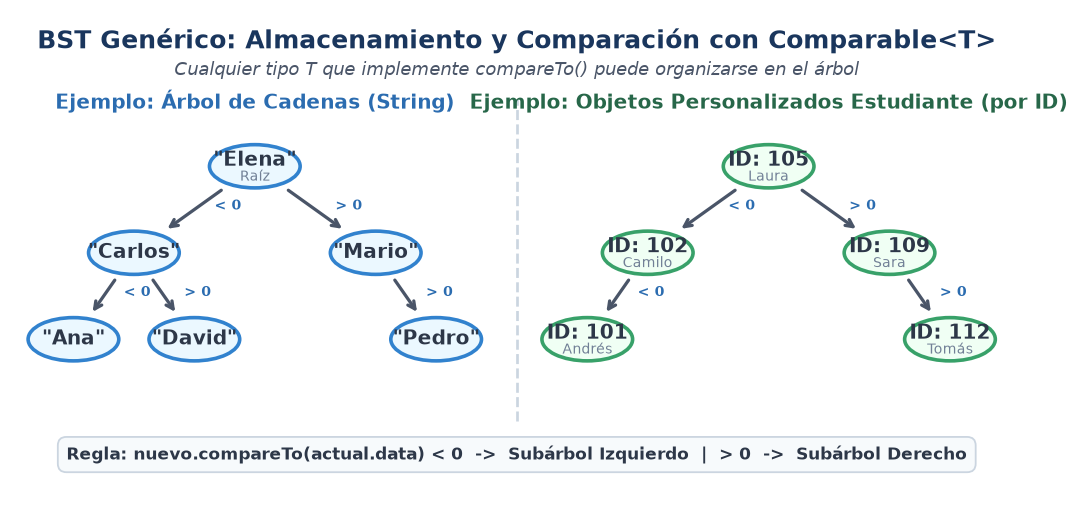
<p><em>Figura 1: Estructura de un BST Genérico en Java almacenando tipos String y objetos Estudiante mediante compareTo().</em></p>
</div>


## 2. Implementación de un Nodo y BST Genérico en Java (`Comparable<T>`)

Analicemos la estructura fundamental de cada nodo y la clase principal del árbol:

```java
// Definicion del Nodo Generico
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left;
    Node<T> right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

// Definicion de la clase BST Generica
public class GenericBST<T extends Comparable<T>> {
    private Node<T> root;

    public GenericBST() {
        this.root = null;
    }
    
    // Metodos principales: insert, search, delete, inOrder...
}
```

Nótese que `Node<T>` encapsula el dato y dos referencias a sus hijos izquierdo y derecho. Gracias al parámetro `<T extends Comparable<T>>`, el compilador de Java verificará en tiempo de compilación que cualquier objeto que intentemos guardar posea un criterio formal de ordenación.


## 3. Operaciones Esenciales en BST Genérico: Búsqueda e Inserción

Repasemos cómo se adaptan la búsqueda y la inserción al modelo genérico utilizando `compareTo`:

### 3.1 Búsqueda (`search`)
Partiendo de la raíz:
1. Si el nodo actual es `null`, el elemento no está en el árbol (retornamos `false` o `null`).
2. Evaluamos `cmp = key.compareTo(current.data)`:
   * Si `cmp == 0`: ¡Elemento encontrado! Retornamos `true` o el nodo correspondiente.
   * Si `cmp < 0`: Continuamos la búsqueda en el subárbol izquierdo (`current.left`).
   * Si `cmp > 0`: Continuamos la búsqueda en el subárbol derecho (`current.right`).

### 3.2 Inserción (`insert`)
1. Si el árbol está vacío (`root == null`), el nuevo elemento se convierte en la raíz.
2. Si no, descendemos de forma similar a la búsqueda:
   * Si `key.compareTo(current.data) < 0`: avanzamos hacia la izquierda. Si `current.left == null`, insertamos el nuevo nodo allí.
   * Si `key.compareTo(current.data) > 0`: avanzamos hacia la derecha. Si `current.right == null`, insertamos el nuevo nodo allí.
   * Si son iguales, se trata de una clave duplicada.

---

### Código Teórico en Acción: Demostración de BST Genérico
Ejecuta el siguiente bloque para observar el funcionamiento interactivo de un Árbol Binario de Búsqueda Genérico en Java almacenando nombres (`String`), visualizando tanto el recorrido in-orden como la jerarquía del árbol y comprobando búsquedas exitosas y fallidas:


In [ ]:
%%writefile EjemploBSTGenerico.java
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

public class EjemploBSTGenerico<T extends Comparable<T>> {
    private Node<T> root;

    public void insert(T data) {
        root = insertRec(root, data);
    }

    private Node<T> insertRec(Node<T> current, T data) {
        if (current == null) {
            return new Node<>(data);
        }
        int cmp = data.compareTo(current.data);
        if (cmp < 0) {
            current.left = insertRec(current.left, data);
        } else if (cmp > 0) {
            current.right = insertRec(current.right, data);
        }
        return current;
    }

    public boolean search(T key) {
        return searchRec(root, key);
    }

    private boolean searchRec(Node<T> current, T key) {
        if (current == null) return false;
        int cmp = key.compareTo(current.data);
        if (cmp == 0) return true;
        if (cmp < 0) return searchRec(current.left, key);
        return searchRec(current.right, key);
    }

    public void inOrder() {
        inOrderRec(root);
        System.out.println();
    }

    private void inOrderRec(Node<T> node) {
        if (node != null) {
            inOrderRec(node.left);
            System.out.print(node.data + " ");
            inOrderRec(node.right);
        }
    }

    // Visualizador de la estructura jerarquica del arbol
    public void printTree() {
        printTreeRec(root, "", false);
    }

    private void printTreeRec(Node<T> node, String prefix, boolean isLeft) {
        if (node != null) {
            System.out.println(prefix + (isLeft ? "|-- " : "\\-- ") + node.data);
            printTreeRec(node.left, prefix + (isLeft ? "|   " : "    "), true);
            printTreeRec(node.right, prefix + (isLeft ? "|   " : "    "), false);
        }
    }

    public static void main(String[] args) {
        System.out.println("==================================================");
        System.out.println("  DEMOSTRACION: BST GENERICO EN ACCION (String)   ");
        System.out.println("==================================================");
        EjemploBSTGenerico<String> arbolNombres = new EjemploBSTGenerico<>();

        // Insertamos nombres en orden no ordenado
        String[] nombres = {"Elena", "Carlos", "Mario", "Ana", "David", "Pedro"};
        System.out.println("Insertando elementos: Elena, Carlos, Mario, Ana, David, Pedro");
        for (String n : nombres) {
            arbolNombres.insert(n);
        }

        System.out.println("\n1. Recorrido In-Order (debe aparecer ordenado alfabeticamente):");
        System.out.print("   -> ");
        arbolNombres.inOrder();

        System.out.println("\n2. Visualizacion de la Estructura Jerarquica del Arbol:");
        arbolNombres.printTree();

        System.out.println("\n3. Pruebas de Busqueda:");
        System.out.println("   - Busqueda 'Carlos': " + arbolNombres.search("Carlos") + " (Esperado: true)");
        System.out.println("   - Busqueda 'Pedro':  " + arbolNombres.search("Pedro")  + " (Esperado: true)");
        System.out.println("   - Busqueda 'Zulma':  " + arbolNombres.search("Zulma")  + " (Esperado: false)");
    }
}


Writing EjemploBSTGenerico.java


In [ ]:
!javac EjemploBSTGenerico.java
!java EjemploBSTGenerico


[0.024s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.024s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
  DEMOSTRACION: BST GENERICO EN ACCION (String)   
Insertando elementos: Elena, Carlos, Mario, Ana, David, Pedro

1. Recorrido In-Order (debe aparecer ordenado alfabeticamente):
   -> Ana Carlos David Elena Mario Pedro 

2. Visualizacion de la Estructura Jerarquica del Arbol:
\-- Elena
    |-- Carlos
    |   |-- Ana
    |   \-- David
    \-

## 4. El Desafío de la Eliminación en un BST (`Delete`)

Hasta este punto, modificar el árbol mediante `insert` ha sido relativamente directo porque **toda nueva clave siempre se inserta como una hoja**, sin perturbar la estructura de los nodos que ya existen.

Sin embargo, **eliminar un nodo (`Delete`) es la operación más delicada y desafiante en un BST**, por las siguientes razones:
1. **Pérdida de Conectividad:** El nodo a eliminar puede estar en el interior del árbol o incluso en la raíz. Desconectarlo sin cuidado dejaría huérfanos a sus descendientes.
2. **Preservación Invariable de la Propiedad BST:** Tras la eliminación, el árbol resultante **debe seguir siendo un Árbol Binario de Búsqueda válido**. Es decir, para cada nodo restante, todo elemento en su subárbol izquierdo debe ser menor y todo elemento en su subárbol derecho debe ser mayor.

Para resolver este desafío de manera sistemática y rigurosa, descomponemos la operación en **tres casos fundamentales** según el número de hijos que posea el nodo a eliminar.


## 5. Los Tres Casos de Eliminación (Análisis Paso a Paso y Diagramas)

Sea $N$ el nodo que deseamos eliminar del árbol:

### 5.1 Caso 1: El nodo a eliminar es una HOJA (0 hijos)
* **Condición:** `N.left == null && N.right == null`.
* **Acción:** Es el caso más simple. Como el nodo no tiene descendientes, no hay subárboles en riesgo de quedar huérfanos. Simplemente se actualiza el puntero del nodo padre para que apunte a `null`. Si el nodo es la raíz, el árbol queda vacío.

<div align="center">
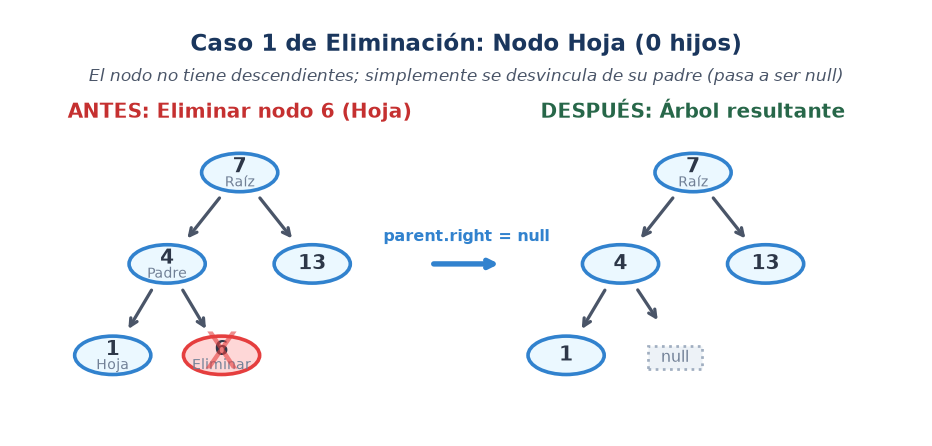
<p><em>Figura 2: Caso 1: Eliminación de un nodo hoja (nodo 6). El puntero del padre pasa a ser null directamente.</em></p>
</div>

---

### 5.2 Caso 2: El nodo a eliminar tiene UN SOLO HIJO (izquierdo o derecho)
* **Condición:** Uno de los hijos es `null` y el otro es no nulo (`N.left == null ^ N.right == null`).
* **Acción:** Se realiza una **promoción directa** (denominada en inglés *bypass*). El único hijo del nodo $N$ pasa a ocupar el lugar de $N$, conectándose directamente con el padre de $N$.
* **¿Por qué se preserva la propiedad BST?** Si $N$ estaba en el subárbol izquierdo del padre de $N$, todos los descendientes de $N$ son por definición menores que dicho padre. Por lo tanto, al conectar al hijo único directamente con el abuelo, la relación de orden se mantiene intacta.

<div align="center">
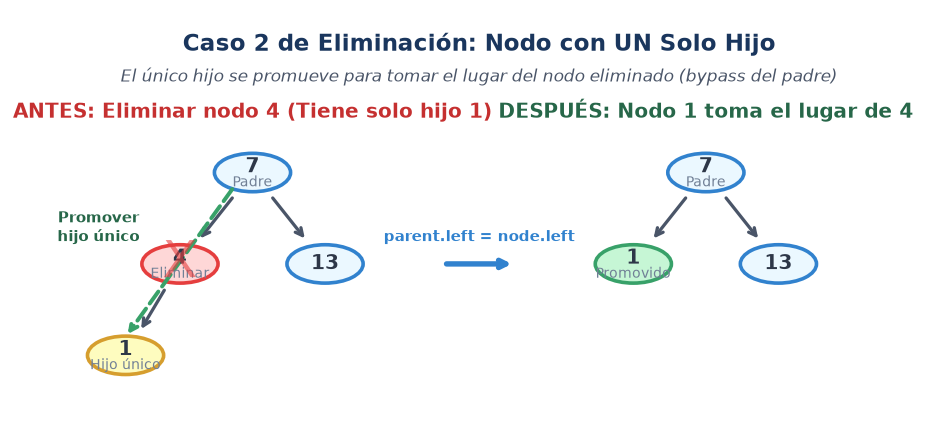
<p><em>Figura 3: Caso 2: Eliminación de un nodo con un solo hijo (nodo 4). El hijo único (nodo 1) se promueve para ocupar el lugar de 4.</em></p>
</div>

---

### 5.3 Caso 3: El nodo a eliminar tiene DOS HIJOS
* **Condición:** `N.left != null && N.right != null`.
* **El dilema:** Si el nodo $N$ tiene dos subárboles completos debajo de él, ¿quién puede tomar su lugar en el árbol sin violar la propiedad de orden?
* **La solución:** Debemos elegir un nodo sustituto que cumpla estrictamente dos condiciones:
  1. Ser **mayor** que todos los elementos del subárbol izquierdo de $N$.
  2. Ser **menor** que todos los elementos restantes del subárbol derecho de $N$.

El candidato ideal es el **Sucesor In-Orden** ($X = \text{Next}(N)$). El sucesor in-orden es el elemento con la clave más pequeña estrictamente mayor que $N$. En un BST, se encuentra ubicado en el **nodo más a la izquierda del subárbol derecho** (`LeftDescendant(N.right)`).

> **Propiedad Fundamental del Sucesor:**  
> Por definición, el nodo más a la izquierda de cualquier subárbol **NUNCA puede tener hijo izquierdo** (`X.left == null`). A lo sumo, tendrá un hijo derecho.

Por tanto, el procedimiento del Caso 3 consta de los siguientes pasos:
1. Localizar el sucesor in-orden $X = \text{Next}(N)$ en el subárbol derecho de $N$.
2. Copiar el dato de $X$ en el nodo $N$ (reemplazo de valor).
3. Eliminar físicamente a $X$ de su posición original en el subárbol derecho. Como $X$ a lo sumo tiene hijo derecho, su eliminación corresponde únicamente al **Caso 1** o al **Caso 2**, ¡lo cual ya sabemos resolver trivialmente!

<div align="center">
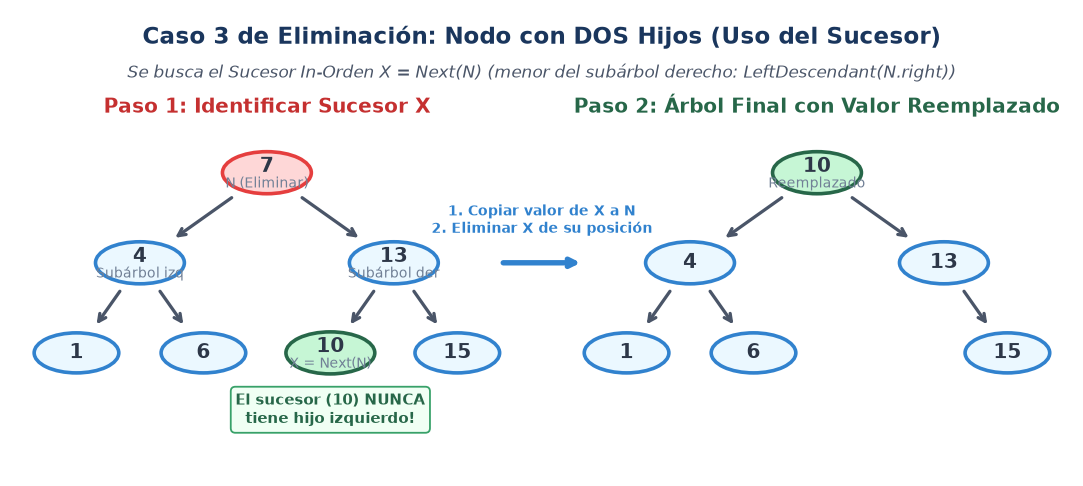
<p><em>Figura 4: Caso 3: Eliminación de un nodo con dos hijos (nodo 7). Se localiza el sucesor in-orden X = 10, se copia su valor y se elimina 10 de su ubicación original.</em></p>
</div>


## 6. La Perspectiva Formal de Daniel Kane (UCSD)

En la perspectiva de Daniel Kane (University of California, San Diego), el algoritmo de eliminación se formula de una manera sumamente compacta y elegante:

```text
Delete(N)
if N.Right == null:
    Remove N, promote N.Left
else:
    X <- Next(N)
    \ Garantía estructural: X.Left == null
    Replace N by X, promote X.Right
```

### ¿Por qué esta formulación coincide con los tres casos?
* Si `N.Right == null`:
  - Si `N.Left == null` también, se promueve `null` $\implies$ **Caso 1 (Hoja)**.
  - Si `N.Left != null`, se promueve `N.Left` $\implies$ **Caso 2 (Un solo hijo)**.
* Si `N.Right != null`:
  - Se busca $X = \text{Next}(N) = \text{LeftDescendant}(N.\text{Right})$.
  - Dado que $X$ es el descendiente más a la izquierda, forzosamente `X.Left == null`.
  - Se reemplaza el contenido de $N$ por $X$, y se promueve `X.Right` en la posición donde estaba $X$ $\implies$ **Caso 3 (Dos hijos)**.

---

### Análisis del Problema de Daniel Kane
Daniel Kane se plantea la siguiente pregunta fundamental:
> *¿Qué árbol se obtiene cuando el nodo 1 es eliminado del árbol ilustrado a continuación?*

Sigamos el algoritmo paso a paso sobre el árbol de la pregunta:
1. El nodo a eliminar es $N = 1$.
2. Comprobamos si tiene hijo derecho: Sí, su hijo derecho es la raíz del subárbol encabezado por $6$.
3. Buscamos el sucesor in-orden $X = \text{Next}(1)$:
   - Vamos a la derecha: nodo $6$.
   - Bajamos por la izquierda todo lo posible: nodo $2$. Como $2$ no tiene hijo izquierdo, **$X = 2$ es el sucesor in-orden**.
4. El sucesor $2$ tiene un hijo derecho (el subárbol encabezado por el nodo $4$).
5. Reemplazamos el valor de $1$ por $2$.
6. Desvinculamos el nodo $2$ original y promovemos su hijo derecho ($4$) para que pase a ser el nuevo hijo izquierdo de $6$.

El resultado corresponde a:

<div align="center">
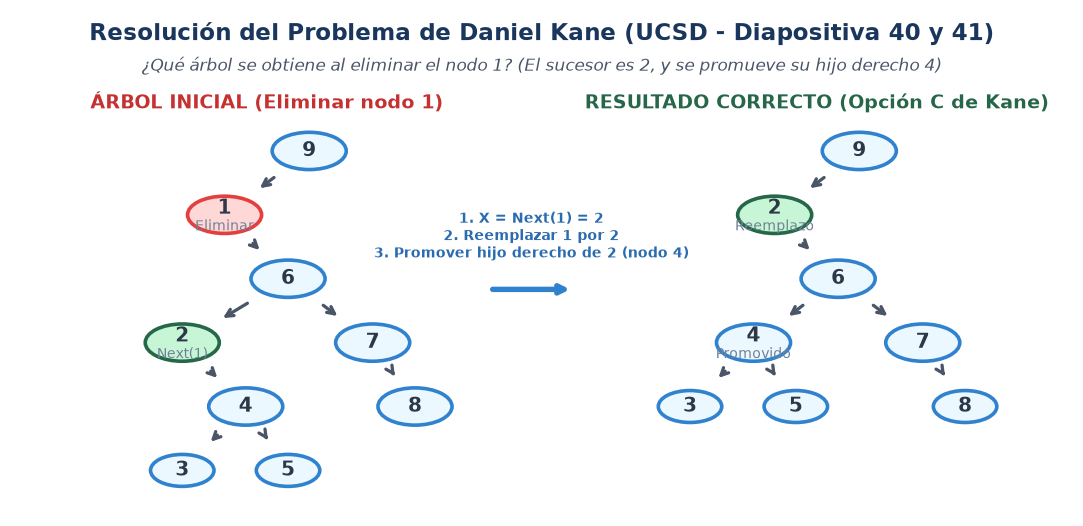
<p><em>Figura 5: Resolución paso a paso del ejercicio de Daniel Kane: Eliminación del nodo 1, ascenso del sucesor 2 y promoción del subárbol con raíz en 4.</em></p>
</div>


## 7. Algoritmo Completo de Eliminación en Java y Demostración en Acción

En Java, la forma más limpia y robusta de implementar la eliminación es mediante el patrón de **reasignación recursiva**. En este patrón, cada llamada recursiva a `deleteRec(Node<T> current, T key)` retorna la referencia actualizada de la raíz del subárbol procesado:

```java
public class GenericBST<T extends Comparable<T>> {
    private Node<T> root;

    public void delete(T key) {
        root = deleteRec(root, key);
    }

    private Node<T> deleteRec(Node<T> current, T key) {
        // Arbol o subarbol vacio
        if (current == null) {
            return null;
        }

        int cmp = key.compareTo(current.data);

        // 1. Descender por el arbol buscando la clave
        if (cmp < 0) {
            current.left = deleteRec(current.left, key);
        } else if (cmp > 0) {
            current.right = deleteRec(current.right, key);
        } else {
            // Clave encontrada: current es el nodo a eliminar.

            // CASO 1 y CASO 2: Nodo sin hijo izquierdo
            if (current.left == null) {
                return current.right; // Promueve hijo derecho (o null si es hoja)
            }
            // CASO 2: Nodo sin hijo derecho
            else if (current.right == null) {
                return current.left;  // Promueve hijo izquierdo
            }

            // CASO 3: Nodo con DOS hijos
            // Encontrar el sucesor in-orden (minimo del subarbol derecho)
            current.data = minValue(current.right);

            // Eliminar fisicamente el sucesor del subarbol derecho
            current.right = deleteRec(current.right, current.data);
        }

        return current;
    }

    // Metodo auxiliar para hallar el sucesor in-orden (LeftDescendant)
    private T minValue(Node<T> node) {
        T minVal = node.data;
        while (node.left != null) {
            minVal = node.left.data;
            node = node.left;
        }
        return minVal;
    }
}
```

---

### Código Teórico en Acción: Validación del Algoritmo de Daniel Kane y Casos de Eliminación
El siguiente bloque compila y ejecuta en tiempo real el árbol exacto presentado por Daniel Kane (UCSD), ejecuta la eliminación del nodo 1, además de ilustrar la eliminación de hojas y nodos con un solo hijo mediante diagramas visuales en consola:


In [3]:
%%writefile DemostracionBSTDelete.java
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

public class DemostracionBSTDelete<T extends Comparable<T>> {
    private Node<T> root;

    public void insert(T data) {
        root = insertRec(root, data);
    }

    private Node<T> insertRec(Node<T> current, T data) {
        if (current == null) return new Node<>(data);
        int cmp = data.compareTo(current.data);
        if (cmp < 0) current.left = insertRec(current.left, data);
        else if (cmp > 0) current.right = insertRec(current.right, data);
        return current;
    }

    // Algoritmo Formal de Daniel Kane (UCSD Slide 39)
    public void deleteKane(T key) {
        root = deleteKaneRec(root, key);
    }

    private Node<T> deleteKaneRec(Node<T> current, T key) {
        if (current == null) return null;

        int cmp = key.compareTo(current.data);
        if (cmp < 0) {
            current.left = deleteKaneRec(current.left, key);
        } else if (cmp > 0) {
            current.right = deleteKaneRec(current.right, key);
        } else {
            // Regla Kane Slide 39: if N.right == null: promote N.left
            if (current.right == null) {
                return current.left;
            } else {
                // X <- Next(N): LeftDescendant(N.right)
                if (current.right.left == null) {
                    // El hijo derecho directo es el sucesor
                    current.right.left = current.left;
                    return current.right;
                } else {
                    // Buscar el nodo mas a la izquierda y su padre
                    Node<T> parentX = current.right;
                    Node<T> X = current.right.left;
                    while (X.left != null) {
                        parentX = X;
                        X = X.left;
                    }
                    // Promover X.right para ocupar el lugar de X
                    parentX.left = X.right;
                    // Asignar el valor de X al nodo actual
                    current.data = X.data;
                }
            }
        }
        return current;
    }

    // Eliminacion estandar de 3 casos
    public void deleteStandard(T key) {
        root = deleteStandardRec(root, key);
    }

    private Node<T> deleteStandardRec(Node<T> current, T key) {
        if (current == null) return null;
        int cmp = key.compareTo(current.data);
        if (cmp < 0) {
            current.left = deleteStandardRec(current.left, key);
        } else if (cmp > 0) {
            current.right = deleteStandardRec(current.right, key);
        } else {
            if (current.left == null) return current.right;
            if (current.right == null) return current.left;
            current.data = minValue(current.right);
            current.right = deleteStandardRec(current.right, current.data);
        }
        return current;
    }

    private T minValue(Node<T> node) {
        T minVal = node.data;
        while (node.left != null) {
            minVal = node.left.data;
            node = node.left;
        }
        return minVal;
    }

    public void inOrder() {
        inOrderRec(root);
        System.out.println();
    }

    private void inOrderRec(Node<T> node) {
        if (node != null) {
            inOrderRec(node.left);
            System.out.print(node.data + " ");
            inOrderRec(node.right);
        }
    }

    public void printTree() {
        printTreeRec(root, "", false);
    }

    private void printTreeRec(Node<T> node, String prefix, boolean isLeft) {
        if (node != null) {
            System.out.println(prefix + (isLeft ? "|-- " : "\\-- ") + node.data);
            printTreeRec(node.left, prefix + (isLeft ? "|   " : "    "), true);
            printTreeRec(node.right, prefix + (isLeft ? "|   " : "    "), false);
        }
    }

    public static void main(String[] args) {
        System.out.println("==================================================================");
        System.out.println(" DEMOSTRACION EN ACCION: RESOLUCION PROBLEMA DANIEL KANE (UCSD)   ");
        System.out.println("==================================================================");
        DemostracionBSTDelete<Integer> bst = new DemostracionBSTDelete<>();

        // Construimos el arbol de la diapositiva 40 de Kane:
        // Claves: 9, 1, 6, 2, 7, 4, 8, 3, 5
        int[] datos = {9, 1, 6, 2, 7, 4, 8, 3, 5};
        for (int d : datos) bst.insert(d);

        System.out.println("Arbol Inicial de la Diapositiva 40:");
        System.out.print("In-Order: ");
        bst.inOrder();
        System.out.println("Estructura visual:");
        bst.printTree();

        System.out.println("\n>>> Ejecutando bst.deleteKane(1)...");
        System.out.println("    - El nodo 1 tiene hijo derecho (raiz 6)");
        System.out.println("    - Su sucesor in-orden es X = 2 (el menor del subarbol derecho)");
        System.out.println("    - El nodo 1 toma el valor 2 y se promueve el hijo derecho de 2 (nodo 4)");
        bst.deleteKane(1);

        System.out.println("\nArbol Resultante tras eliminar el nodo 1:");
        System.out.print("In-Order resultante: ");
        bst.inOrder();
        System.out.println("Estructura visual resultante:");
        bst.printTree();

        System.out.println("\n==================================================================");
        System.out.println(" Confirmacion: El resultado coincide exactamente con la OPCION C  ");
        System.out.println(" de las diapositivas de Daniel Kane (UC San Diego)!               ");
        System.out.println("==================================================================");

        System.out.println("\n--- Demostracion de Caso 1 (Hoja: eliminar 8) ---");
        bst.deleteStandard(8);
        bst.printTree();

        System.out.println("\n--- Demostracion de Caso 2 (Un solo hijo: eliminar 7) ---");
        bst.deleteStandard(7);
        bst.printTree();
    }
}


Writing DemostracionBSTDelete.java


In [4]:
!javac DemostracionBSTDelete.java
!java DemostracionBSTDelete


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
 DEMOSTRACION EN ACCION: RESOLUCION PROBLEMA DANIEL KANE (UCSD)   
Arbol Inicial de la Diapositiva 40:
In-Order: 1 2 3 4 5 6 7 8 9 
Estructura visual:
\-- 9
    |-- 1
    |   \-- 6
    |       |-- 2
    |       |   \-- 4
    |       |       |-- 3
    |       |       \-- 5
    |       \-- 7
    |           \-- 8

>>> Ejecutando bst.deleteKan

## 8. Análisis de Complejidad Temporal (Mejor Caso vs. Peor Caso)

Analicemos las operaciones que componen la eliminación de un nodo con clave $k$:
1. **Búsqueda del nodo $N$:** Descender desde la raíz hasta encontrar la clave toma a lo sumo un camino de longitud igual a la altura del árbol: $O(h)$.
2. **Localización del sucesor (en el Caso 3):** Descender desde $N.\text{right}$ hasta su nodo más a la izquierda también está acotado por la altura del árbol: $O(h)$.
3. **Reconexión de punteros y asignaciones:** Son operaciones elementales en memoria: $O(1)$.

Por lo tanto, la complejidad temporal total de la operación `delete` es:

$$T(n) = O(h)$$

Donde $h$ es la altura del árbol binario de búsqueda con $n$ nodos.

| Caso | Altura del Árbol ($h$) | Complejidad de `Delete` | Escenario |
| :--- | :---: | :---: | :--- |
| **Mejor Caso / Balanceado** | $\approx \log_2(n)$ | $\mathbf{O(\log n)}$ | Árbol estructurado de manera equilibrada tras inserciones aleatorias. |
| **Caso Promedio** | $O(\log n)$ | $\mathbf{O(\log n)}$ | Inserciones y eliminaciones con distribución probabilística uniforme. |
| **Peor Caso (Degenerado)** | $n$ | $\mathbf{O(n)}$ | Elementos insertados en orden estrictamente creciente o decreciente (el árbol se convierte en una lista enlazada). |

> **Reflexión para las próximas clases:**  
> Como podemos advertir, la eficiencia del BST depende críticamente de su **altura** $h$. Si el árbol degenera en una lista enlazada, perdemos la ventaja logarítmica y la eliminación costará $O(n)$. Esto motivará en las clases siguientes el estudio de técnicas para mantener el árbol balanceado automáticamente.


## 9. Ejercicios Prácticos

A continuación, pondremos en práctica los conceptos estudiados mediante 5 ejercicios de programación en Java. Ejecuta las celdas en orden en Google Colab para compilar y probar tus soluciones.

---

### Ejercicio 1: Implementación de BST Genérico (`BSTGenericSearch.java`)
**Objetivo:** Implementar la estructura básica de un Árbol Binario de Búsqueda Genérico en Java (`GenericBST<T extends Comparable<T>>`) con soporte para inserción, recorrido in-order y búsqueda recursiva.

Completa la lógica del método `searchRec(Node<T> current, T key)` comparando adecuadamente los elementos mediante `compareTo`.


In [ ]:
%%writefile BSTGenericSearch.java
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

public class BSTGenericSearch<T extends Comparable<T>> {
    private Node<T> root;

    public void insert(T data) {
        root = insertRec(root, data);
    }

    private Node<T> insertRec(Node<T> current, T data) {
        if (current == null) {
            return new Node<>(data);
        }
        int cmp = data.compareTo(current.data);
        if (cmp < 0) {
            current.left = insertRec(current.left, data);
        } else if (cmp > 0) {
            current.right = insertRec(current.right, data);
        }
        return current;
    }

    public boolean search(T key) {
        return searchRec(root, key);
    }

    private boolean searchRec(Node<T> current, T key) {
        // CASO BASE: Si el nodo actual es null, el elemento no esta
        if (current == null) {
            return false;
        }

        // TODO: Compara 'key' con 'current.data' usando compareTo()
        // 1. Si key es igual a current.data (cmp == 0), retorna true.
        // 2. Si key es menor (cmp < 0), busca en current.left.
        // 3. Si key es mayor (cmp > 0), busca en current.right.
        int cmp = key.compareTo(current.data);
        if (cmp == 0) {
            return true;
        } else if (cmp < 0) {
            return searchRec(current.left, key);
        } else {
            return searchRec(current.right, key);
        }
    }

    public void inOrder() {
        inOrderRec(root);
        System.out.println();
    }

    private void inOrderRec(Node<T> node) {
        if (node != null) {
            inOrderRec(node.left);
            System.out.print(node.data + " ");
            inOrderRec(node.right);
        }
    }

    public static void main(String[] args) {
        System.out.println("=== PRUEBA 1: BST Generico con Cadenas (String) ===");
        BSTGenericSearch<String> bstStrings = new BSTGenericSearch<>();
        String[] nombres = {"Elena", "Carlos", "Mario", "Ana", "David", "Pedro"};
        for (String n : nombres) {
            bstStrings.insert(n);
        }

        System.out.print("Recorrido In-Order (Alfabetico): ");
        bstStrings.inOrder();

        System.out.println("Busqueda 'Carlos': " + bstStrings.search("Carlos") + " (Esperado: true)");
        System.out.println("Busqueda 'Zulma':  " + bstStrings.search("Zulma") + " (Esperado: false)");

        System.out.println("\n=== PRUEBA 2: BST Generico con Enteros (Integer) ===");
        BSTGenericSearch<Integer> bstInts = new BSTGenericSearch<>();
        int[] valores = {50, 30, 70, 20, 40, 60, 80};
        for (int v : valores) {
            bstInts.insert(v);
        }

        System.out.print("Recorrido In-Order (Ordenado): ");
        bstInts.inOrder();

        System.out.println("Busqueda 40: " + bstInts.search(40) + " (Esperado: true)");
        System.out.println("Busqueda 99: " + bstInts.search(99) + " (Esperado: false)");
    }
}


In [ ]:
!javac BSTGenericSearch.java
!java BSTGenericSearch


---
### Ejercicio 2: Programación de la Eliminación en BST (`BSTDelete.java`)
**Objetivo:** Programar el algoritmo completo de eliminación en un BST Genérico, cubriendo explícitamente los 3 casos:
1. **Caso 1:** El nodo es una hoja (retornar `null`).
2. **Caso 2:** El nodo tiene un único hijo (retornar el hijo no nulo).
3. **Caso 3:** El nodo tiene dos hijos (obtención del sucesor in-orden mediante `minValue` y eliminación recursiva).

Completa el cuerpo del método `deleteRec` en la plantilla de código.


In [ ]:
%%writefile BSTDelete.java
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

public class BSTDelete<T extends Comparable<T>> {
    private Node<T> root;

    public void insert(T data) {
        root = insertRec(root, data);
    }

    private Node<T> insertRec(Node<T> current, T data) {
        if (current == null) return new Node<>(data);
        int cmp = data.compareTo(current.data);
        if (cmp < 0) current.left = insertRec(current.left, data);
        else if (cmp > 0) current.right = insertRec(current.right, data);
        return current;
    }

    public void delete(T key) {
        root = deleteRec(root, key);
    }

    private Node<T> deleteRec(Node<T> current, T key) {
        if (current == null) {
            return null;
        }

        int cmp = key.compareTo(current.data);

        if (cmp < 0) {
            current.left = deleteRec(current.left, key);
        } else if (cmp > 0) {
            current.right = deleteRec(current.right, key);
        } else {
            // NODO ENCONTRADO (current.data == key)

            // TODO: CASOS 1 Y 2 (El nodo tiene 0 o 1 hijo)
            // - Si current.left es null, retorna current.right
            // - Si current.right es null, retorna current.left
            if (current.left == null) {
                return current.right;
            } else if (current.right == null) {
                return current.left;
            }

            // TODO: CASO 3 (El nodo tiene DOS hijos)
            // 1. Encuentra el valor minimo en el subarbol derecho (sucesor in-orden)
            // 2. Asigna ese valor a current.data
            // 3. Elimina recursivamente el sucesor del subarbol derecho:
            //    current.right = deleteRec(current.right, current.data);
            current.data = minValue(current.right);
            current.right = deleteRec(current.right, current.data);
        }

        return current;
    }

    // Metodo auxiliar para hallar el valor minimo en un subarbol
    private T minValue(Node<T> node) {
        T minVal = node.data;
        while (node.left != null) {
            minVal = node.left.data;
            node = node.left;
        }
        return minVal;
    }

    public void inOrder() {
        inOrderRec(root);
        System.out.println();
    }

    private void inOrderRec(Node<T> node) {
        if (node != null) {
            inOrderRec(node.left);
            System.out.print(node.data + " ");
            inOrderRec(node.right);
        }
    }

    public static void main(String[] args) {
        BSTDelete<Integer> bst = new BSTDelete<>();

        // Construimos el arbol de ejemplo: 7, 4, 13, 1, 6, 10, 15
        int[] vals = {7, 4, 13, 1, 6, 10, 15};
        for (int v : vals) bst.insert(v);

        System.out.println("Arbol inicial:");
        System.out.print("In-Order: ");
        bst.inOrder();

        System.out.println("\n--- Test 1: Eliminar nodo Hoja (nodo 6) [Caso 1] ---");
        bst.delete(6);
        System.out.print("In-Order resultante: ");
        bst.inOrder();

        System.out.println("\n--- Test 2: Eliminar nodo con 1 Hijo (nodo 4, solo queda 1) [Caso 2] ---");
        bst.delete(4);
        System.out.print("In-Order resultante: ");
        bst.inOrder();

        System.out.println("\n--- Test 3: Eliminar nodo con 2 Hijos (raiz 7) [Caso 3] ---");
        // El sucesor de 7 es 10
        bst.delete(7);
        System.out.print("In-Order resultante: ");
        bst.inOrder();

        System.out.println("\nEstado final correcto!");
    }
}


In [ ]:
!javac BSTDelete.java
!java BSTDelete


---
### Ejercicio 3: Búsqueda de Sucesor y Predecesor In-Orden (`BSTSuccessorPredecessor.java`)
**Objetivo:** Implementar los métodos para encontrar el **Sucesor In-Orden** (`findSuccessor`) y el **Predecesor In-Orden** (`findPredecessor`) de una clave dada en un BST.

Recuerda los dos escenarios estudiados en la clase de Daniel Kane para el Sucesor:
1. **Si el nodo tiene hijo derecho:** El sucesor es el descendiente más a la izquierda del hijo derecho (`LeftDescendant(node.right)`).
2. **Si el nodo NO tiene hijo derecho:** El sucesor es el ancestro más cercano del cual el nodo desciende por la izquierda (`RightAncestor`). En un recorrido desde la raíz, es el último nodo en el que giramos hacia la izquierda.

Completa la lógica en la plantilla.


In [ ]:
%%writefile BSTSuccessorPredecessor.java
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

public class BSTSuccessorPredecessor<T extends Comparable<T>> {
    private Node<T> root;

    public void insert(T data) {
        root = insertRec(root, data);
    }

    private Node<T> insertRec(Node<T> current, T data) {
        if (current == null) return new Node<>(data);
        int cmp = data.compareTo(current.data);
        if (cmp < 0) current.left = insertRec(current.left, data);
        else if (cmp > 0) current.right = insertRec(current.right, data);
        return current;
    }

    // Busca el sucesor in-orden: menor elemento estrictamente mayor a 'key'
    public T findSuccessor(T key) {
        Node<T> current = root;
        Node<T> successor = null;

        while (current != null) {
            int cmp = key.compareTo(current.data);
            if (cmp < 0) {
                // Posible sucesor: guardamos current y vamos a la izquierda
                successor = current;
                current = current.left;
            } else if (cmp > 0) {
                current = current.right;
            } else {
                // Encontramos el nodo: si tiene hijo derecho, el sucesor es el minimo de ese subarbol
                if (current.right != null) {
                    successor = minNode(current.right);
                }
                break;
            }
        }
        return (successor != null) ? successor.data : null;
    }

    // Busca el predecesor in-orden: mayor elemento estrictamente menor a 'key'
    public T findPredecessor(T key) {
        Node<T> current = root;
        Node<T> predecessor = null;

        while (current != null) {
            int cmp = key.compareTo(current.data);
            if (cmp > 0) {
                // Posible predecesor: guardamos current y vamos a la derecha
                predecessor = current;
                current = current.right;
            } else if (cmp < 0) {
                current = current.left;
            } else {
                // Encontramos el nodo: si tiene hijo izquierdo, el predecesor es el maximo de ese subarbol
                if (current.left != null) {
                    predecessor = maxNode(current.left);
                }
                break;
            }
        }
        return (predecessor != null) ? predecessor.data : null;
    }

    private Node<T> minNode(Node<T> node) {
        while (node.left != null) node = node.left;
        return node;
    }

    private Node<T> maxNode(Node<T> node) {
        while (node.right != null) node = node.right;
        return node;
    }

    public static void main(String[] args) {
        BSTSuccessorPredecessor<Integer> bst = new BSTSuccessorPredecessor<>();
        int[] valores = {20, 8, 22, 4, 12, 10, 14};
        for (int v : valores) bst.insert(v);

        System.out.println("Arbol con elementos: 20, 8, 22, 4, 12, 10, 14");

        System.out.println("Sucesor de 8:  " + bst.findSuccessor(8) + " (Esperado: 10)");
        System.out.println("Sucesor de 10: " + bst.findSuccessor(10) + " (Esperado: 12)");
        System.out.println("Sucesor de 14: " + bst.findSuccessor(14) + " (Esperado: 20)");
        System.out.println("Sucesor de 22: " + bst.findSuccessor(22) + " (Esperado: null)");

        System.out.println("\nPredecesor de 8:  " + bst.findPredecessor(8) + " (Esperado: 4)");
        System.out.println("Predecesor de 10: " + bst.findPredecessor(10) + " (Esperado: 8)");
        System.out.println("Predecesor de 20: " + bst.findPredecessor(20) + " (Esperado: 14)");
        System.out.println("Predecesor de 4:  " + bst.findPredecessor(4) + " (Esperado: null)");
    }
}


In [ ]:
!javac BSTSuccessorPredecessor.java
!java BSTSuccessorPredecessor


---
### Ejercicio 4: Eliminación con Predecesor In-Orden (`BSTDeletePredecessor.java`)
**Objetivo:** Explorar la variante simétrica de la eliminación. En el **Caso 3** (nodo con 2 hijos), en lugar de sustituir por el sucesor in-orden del subárbol derecho, utilizaremos el **Predecesor In-Orden** (el elemento con el valor máximo del subárbol izquierdo: `maxNode(current.left)`).

Observa que el predecesor in-orden **nunca tiene hijo derecho** (`predecessor.right == null`), lo que garantiza exactamente la misma facilidad al momento de desvincularlo.

Completa la sustitución por el predecesor en el Caso 3.


In [ ]:
%%writefile BSTDeletePredecessor.java
class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;

    public Node(T data) {
        this.data = data;
        this.left = null;
        this.right = null;
    }
}

public class BSTDeletePredecessor<T extends Comparable<T>> {
    private Node<T> root;

    public void insert(T data) {
        root = insertRec(root, data);
    }

    private Node<T> insertRec(Node<T> current, T data) {
        if (current == null) return new Node<>(data);
        int cmp = data.compareTo(current.data);
        if (cmp < 0) current.left = insertRec(current.left, data);
        else if (cmp > 0) current.right = insertRec(current.right, data);
        return current;
    }

    public void deleteUsingPredecessor(T key) {
        root = deleteRec(root, key);
    }

    private Node<T> deleteRec(Node<T> current, T key) {
        if (current == null) return null;

        int cmp = key.compareTo(current.data);
        if (cmp < 0) {
            current.left = deleteRec(current.left, key);
        } else if (cmp > 0) {
            current.right = deleteRec(current.right, key);
        } else {
            // Caso 1 y Caso 2
            if (current.left == null) return current.right;
            if (current.right == null) return current.left;

            // TODO: CASO 3 USANDO EL PREDECESOR IN-ORDEN
            // 1. Encuentra el valor maximo en el subarbol izquierdo (predecesor)
            // 2. Asigna current.data = maxValue(current.left)
            // 3. Elimina recursivamente el predecesor del subarbol izquierdo:
            //    current.left = deleteRec(current.left, current.data)
            current.data = maxValue(current.left);
            current.left = deleteRec(current.left, current.data);
        }
        return current;
    }

    private T maxValue(Node<T> node) {
        T maxVal = node.data;
        while (node.right != null) {
            maxVal = node.right.data;
            node = node.right;
        }
        return maxVal;
    }

    public void inOrder() {
        inOrderRec(root);
        System.out.println();
    }

    private void inOrderRec(Node<T> node) {
        if (node != null) {
            inOrderRec(node.left);
            System.out.print(node.data + " ");
            inOrderRec(node.right);
        }
    }

    public static void main(String[] args) {
        BSTDeletePredecessor<Integer> bst = new BSTDeletePredecessor<>();
        int[] vals = {50, 30, 70, 20, 40, 60, 80};
        for (int v : vals) bst.insert(v);

        System.out.println("Arbol inicial: 50, 30, 70, 20, 40, 60, 80");
        System.out.print("In-Order inicial: ");
        bst.inOrder();

        System.out.println("\nEliminando la raiz 50 usando el PREDECESOR in-orden (debe ser 40)...");
        bst.deleteUsingPredecessor(50);

        System.out.print("In-Order tras eliminar 50: ");
        bst.inOrder();
        System.out.println("La propiedad de BST se mantiene estrictamente valida!");
    }
}


In [ ]:
!javac BSTDeletePredecessor.java
!java BSTDeletePredecessor


---
### Ejercicio 5: Aplicación Práctica: Sistema de Gestión de Estudiantes (`SistemaEstudiantesBST.java`)
**Objetivo:** Integrar todo lo aprendido en una aplicación del mundo real. Construirás un sistema de gestión escolar donde cada registro es un objeto de la clase `Estudiante` que implementa `Comparable<Estudiante>`, ordenado por su código de matrícula (`id`).

El sistema debe permitir:
1. Insertar nuevos estudiantes.
2. Buscar los datos completos de un estudiante a partir de su `id`.
3. Dar de baja (eliminar) a un estudiante del árbol manteniendo la estructura íntegra.

Completa la implementación y verifica las consultas en el método `main`.


In [ ]:
%%writefile SistemaEstudiantesBST.java
// Clase Estudiante que define su orden natural mediante 'id'
class Estudiante implements Comparable<Estudiante> {
    private int id;
    private String nombre;
    private double promedio;

    public Estudiante(int id, String nombre, double promedio) {
        this.id = id;
        this.nombre = nombre;
        this.promedio = promedio;
    }

    // Constructor de conveniencia para busquedas o eliminaciones por ID
    public Estudiante(int id) {
        this(id, "", 0.0);
    }

    public int getId() { return id; }
    public String getNombre() { return nombre; }
    public double getPromedio() { return promedio; }

    @Override
    public int compareTo(Estudiante otro) {
        // Orden natural por ID ascendente
        return Integer.compare(this.id, otro.id);
    }

    @Override
    public String toString() {
        return String.format("[ID: %d | Nombre: %-10s | Promedio: %.2f]", id, nombre, promedio);
    }
}

class Node<T extends Comparable<T>> {
    T data;
    Node<T> left, right;
    public Node(T data) { this.data = data; }
}

public class SistemaEstudiantesBST {
    private Node<Estudiante> root;

    public void registrar(Estudiante est) {
        root = insertRec(root, est);
    }

    private Node<Estudiante> insertRec(Node<Estudiante> current, Estudiante est) {
        if (current == null) return new Node<>(est);
        int cmp = est.compareTo(current.data);
        if (cmp < 0) current.left = insertRec(current.left, est);
        else if (cmp > 0) current.right = insertRec(current.right, est);
        return current;
    }

    public Estudiante buscarPorId(int id) {
        Estudiante dummy = new Estudiante(id);
        Node<Estudiante> res = searchRec(root, dummy);
        return (res != null) ? res.data : null;
    }

    private Node<Estudiante> searchRec(Node<Estudiante> current, Estudiante target) {
        if (current == null) return null;
        int cmp = target.compareTo(current.data);
        if (cmp == 0) return current;
        if (cmp < 0) return searchRec(current.left, target);
        return searchRec(current.right, target);
    }

    public void darDeBaja(int id) {
        Estudiante dummy = new Estudiante(id);
        root = deleteRec(root, dummy);
    }

    private Node<Estudiante> deleteRec(Node<Estudiante> current, Estudiante target) {
        if (current == null) return null;
        int cmp = target.compareTo(current.data);
        if (cmp < 0) {
            current.left = deleteRec(current.left, target);
        } else if (cmp > 0) {
            current.right = deleteRec(current.right, target);
        } else {
            // Encontrado: aplicar casos de eliminacion
            if (current.left == null) return current.right;
            if (current.right == null) return current.left;

            // Caso 2 hijos: sucesor in-orden
            current.data = minValue(current.right);
            current.right = deleteRec(current.right, current.data);
        }
        return current;
    }

    private Estudiante minValue(Node<Estudiante> node) {
        Estudiante minVal = node.data;
        while (node.left != null) {
            minVal = node.left.data;
            node = node.left;
        }
        return minVal;
    }

    public void listarEstudiantes() {
        inOrder(root);
    }

    private void inOrder(Node<Estudiante> node) {
        if (node != null) {
            inOrder(node.left);
            System.out.println("  " + node.data);
            inOrder(node.right);
        }
    }

    public static void main(String[] args) {
        SistemaEstudiantesBST sistema = new SistemaEstudiantesBST();

        System.out.println("=== Registrando Estudiantes en el BST ===");
        sistema.registrar(new Estudiante(105, "Laura", 4.5));
        sistema.registrar(new Estudiante(102, "Camilo", 3.8));
        sistema.registrar(new Estudiante(109, "Sara", 4.7));
        sistema.registrar(new Estudiante(101, "Andres", 4.1));
        sistema.registrar(new Estudiante(104, "Valentina", 4.3));
        sistema.registrar(new Estudiante(112, "Tomas", 3.9));

        System.out.println("\nListado de Estudiantes Ordenados por Matricula (ID):");
        sistema.listarEstudiantes();

        System.out.println("\n=== Consultando Estudiante con ID 104 ===");
        Estudiante e = sistema.buscarPorId(104);
        System.out.println("Encontrado: " + e);

        System.out.println("\n=== Dando de baja al estudiante con ID 105 (nodo con 2 hijos) ===");
        sistema.darDeBaja(105);

        System.out.println("\nListado actualizado tras la baja:");
        sistema.listarEstudiantes();

        System.out.println("\nSigue existiendo el ID 105?: " + (sistema.buscarPorId(105) != null));
    }
}


In [ ]:
!javac SistemaEstudiantesBST.java
!java SistemaEstudiantesBST


## 10. Bibliografía y Referencias

1. **Kane, Daniel.** *Binary Search Trees: Introduction*. Department of Computer Science and Engineering, University of California, San Diego (UCSD).
2. **Kane, Daniel.** *Binary Search Trees: Search Trees*. Department of Computer Science and Engineering, University of California, San Diego (UCSD).
3. **Kane, Daniel.** *Binary Search Trees: Basic Operations* (Slides 32–42: `Delete(N)`, Successor, LeftDescendant, Case Analysis). Department of Computer Science and Engineering, University of California, San Diego (UCSD).
4. **Goodrich, M. T., Tamassia, R., & Goldwasser, M. H.** (2014). *Data Structures and Algorithms in Java* (6th ed.). John Wiley & Sons. Capítulo 11: *Search Trees*.
5. **Streib, J. T., & Soma, T.** (2017). *Guide to Data Structures: A Concise Introduction Using Java*. Springer. Capítulo 8: *Trees*.
6. **Visualizador Interactivo de BST de la Universidad de San Francisco (USFCA):** [https://www.cs.usfca.edu/~galles/visualization/BST.html](https://www.cs.usfca.edu/~galles/visualization/BST.html)
---
